# Linear and polynomial regression

This notebook tests how pumpkin feature correlation relates to held-out accuracy, then builds a fresh diabetes model and chooses between linear and polynomial techniques.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

## Pumpkin feature experiment

The same cleaning and price normalization used in the data lesson produces a numeric target per bushel. Both candidate features are split together, ensuring that Month and DayOfYear models see identical training and test observations.

In [2]:
data_path = Path("../../../2-Regression/data/US-pumpkins.csv")
assert data_path.is_file(), f"Missing dataset: {data_path.resolve()}"

raw_pumpkins = pd.read_csv(data_path)
columns = ["Date", "Package", "Low Price", "High Price"]
pumpkins = raw_pumpkins.loc[
    raw_pumpkins["Package"].str.contains("bushel", case=False, na=False), columns
].copy()
pumpkins["Date"] = pd.to_datetime(pumpkins["Date"], format="%m/%d/%y", errors="coerce")
for column in ("Low Price", "High Price"):
    pumpkins[column] = pd.to_numeric(pumpkins[column], errors="coerce")
pumpkins = pumpkins.dropna(subset=["Date", "Low Price", "High Price"]).copy()
volume = np.select(
    [
        pumpkins["Package"].str.contains("1 1/9", regex=False),
        pumpkins["Package"].str.contains("1/2", regex=False),
    ],
    [10 / 9, 1 / 2],
    default=1.0,
)
pumpkins["Price per Bushel"] = (
    (pumpkins["Low Price"] + pumpkins["High Price"]) / 2 / volume
)
pumpkins["Month"] = pumpkins["Date"].dt.month
pumpkins["DayOfYear"] = pumpkins["Date"].dt.dayofyear

assert len(pumpkins) == 415
assert np.isfinite(pumpkins[["Month", "DayOfYear", "Price per Bushel"]]).all().all()
pumpkins[["Month", "DayOfYear", "Price per Bushel"]].head()

,Month,DayOfYear,Price per Bushel
70,9,268,13.5
71,9,268,16.2
72,10,275,16.2
73,10,275,15.3
74,10,282,13.5


In [3]:
pumpkin_features = pumpkins[["Month", "DayOfYear"]]
pumpkin_target = pumpkins["Price per Bushel"]
X_train, X_test, y_train, y_test = train_test_split(
    pumpkin_features, pumpkin_target, test_size=0.2, random_state=42
)

pumpkin_rows = []
pumpkin_predictions = {}
for feature in pumpkin_features.columns:
    model = LinearRegression().fit(X_train[[feature]], y_train)
    predictions = model.predict(X_test[[feature]])
    pumpkin_predictions[feature] = predictions
    pumpkin_rows.append(
        {
            "Feature": feature,
            "Correlation": pumpkins[feature].corr(pumpkin_target),
            "R2": r2_score(y_test, predictions),
            "MAE": mean_absolute_error(y_test, predictions),
            "RMSE": root_mean_squared_error(y_test, predictions),
        }
    )

pumpkin_results = pd.DataFrame(pumpkin_rows).set_index("Feature")
assert np.isfinite(pumpkin_results.to_numpy()).all()
pumpkin_results.round(4)

,Correlation,R2,MAE,RMSE
Feature,,,,
Month,-0.1491,-0.0131,9.1761,10.4587
DayOfYear,-0.1669,-0.0026,9.1047,10.4047


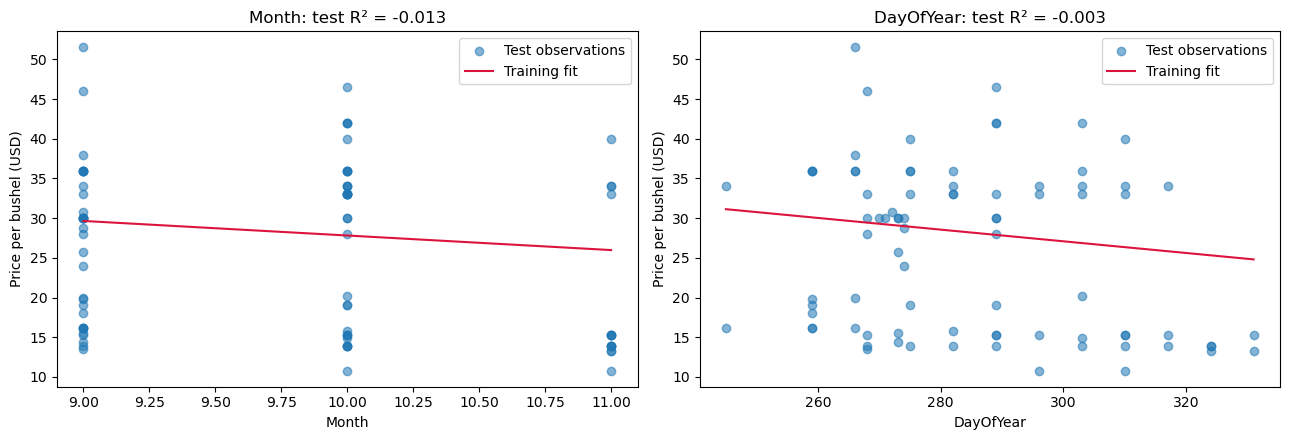

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for axis, feature in zip(axes, pumpkin_features.columns):
    values = X_test[feature].to_numpy()
    predictions = pumpkin_predictions[feature]
    order = np.argsort(values)
    axis.scatter(values, y_test, alpha=0.55, label="Test observations")
    axis.plot(values[order], predictions[order], color="crimson", label="Training fit")
    axis.set(
        title=f"{feature}: test R² = {pumpkin_results.loc[feature, 'R2']:.3f}",
        xlabel=feature,
        ylabel="Price per bushel (USD)",
    )
    axis.legend()
fig.tight_layout()
plt.show()

Both calendar features have weak negative correlation and negative held-out R². DayOfYear is slightly better, but neither one-feature line is useful for prediction. Correlation describes association in this sample; it does not measure generalization or establish causation.

## Fresh diabetes model

Degree-1 and degree-2 transformations are compared on one deterministic split. Each pipeline learns its polynomial expansion and scaling from training data only, preventing test-set preprocessing leakage.

In [5]:
diabetes = load_diabetes(as_frame=True)
X_train, X_test, y_train, y_test = train_test_split(
    diabetes.data, diabetes.target, test_size=0.25, random_state=42
)

diabetes_models = {
    "Degree 1 (linear)": make_pipeline(
        PolynomialFeatures(degree=1, include_bias=False), StandardScaler(), LinearRegression()
    ),
    "Degree 2 (polynomial)": make_pipeline(
        PolynomialFeatures(degree=2, include_bias=False), StandardScaler(), LinearRegression()
    ),
}
diabetes_rows = []
diabetes_predictions = {}
for name, model in diabetes_models.items():
    model.fit(X_train, y_train)
    assert model.named_steps["standardscaler"].n_samples_seen_ == len(X_train)
    predictions = model.predict(X_test)
    diabetes_predictions[name] = predictions
    diabetes_rows.append(
        {
            "Model": name,
            "R2": r2_score(y_test, predictions),
            "MAE": mean_absolute_error(y_test, predictions),
            "RMSE": root_mean_squared_error(y_test, predictions),
        }
    )

diabetes_results = pd.DataFrame(diabetes_rows).set_index("Model")
assert np.isfinite(diabetes_results.to_numpy()).all()
diabetes_results.round(4)

,R2,MAE,RMSE
Model,,,
Degree 1 (linear),0.4849,41.5485,53.3696
Degree 2 (polynomial),0.4242,44.0300,56.4248


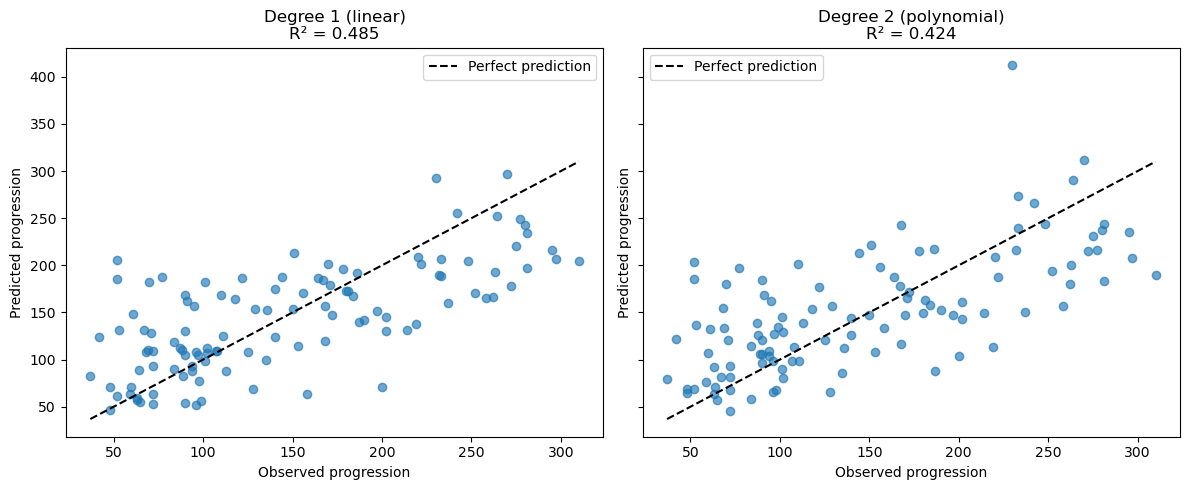

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
limits = [float(y_test.min()), float(y_test.max())]
for axis, (name, predictions) in zip(axes, diabetes_predictions.items()):
    axis.scatter(y_test, predictions, alpha=0.65)
    axis.plot(limits, limits, linestyle="--", color="black", label="Perfect prediction")
    axis.set(
        title=f"{name}\nR² = {diabetes_results.loc[name, 'R2']:.3f}",
        xlabel="Observed progression",
        ylabel="Predicted progression",
    )
    axis.legend()
fig.tight_layout()
plt.show()

In [7]:
linear = diabetes_results.loc["Degree 1 (linear)"]
polynomial = diabetes_results.loc["Degree 2 (polynomial)"]
polynomial_materially_improves = (
    polynomial["R2"] >= linear["R2"] + 0.02
    and polynomial["RMSE"] <= linear["RMSE"] * 0.95
)
selected_model = "Degree 2 (polynomial)" if polynomial_materially_improves else "Degree 1 (linear)"
print(f"Selected model: {selected_model}")
print("Reason: prefer the simpler model unless polynomial test R² and RMSE improve materially.")

Selected model: Degree 1 (linear)
Reason: prefer the simpler model unless polynomial test R² and RMSE improve materially.


## Conclusion and limitations

The degree-2 model is worse on held-out R², MAE, and RMSE, so the linear model is the justified choice. Its R² still leaves substantial variation unexplained. The diabetes dataset is small and observational, the target is a constructed progression measure, and this classroom split does not demonstrate clinical validity, causality, or transport to another population.